# 01 – Data Understanding, Data Quality & EDA

**Project:** Industrial AI Predictive Maintenance for Wind Turbines

**Dataset:** CARE to Compare – Version 6

**Environment:** Google Colab & Google Drive

## Objective

Explore the CARE-to-Compare dataset to understand its
structure, SCADA features, event metadata, temporal
characteristics, and data quality.

The initial analysis focuses on Wind Farm A.

## Analysis Workflow

1. Environment Setup
2. Dataset Overview
3. Event Metadata Analysis
4. Feature Metadata Analysis
5. SCADA Data Structure
6. Temporal Analysis
7. Data Quality Analysis
8. Operating Status Analysis
9. Sensor Data Exploration
10. Cross-Farm Dataset Comparison
11. Key Findings and Conclusions

## 1. Environment Setup

This section initializes the Google Colab environment
and connects Google Drive to access the CARE-to-Compare dataset.

The original dataset files are used for read-only analysis.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pathlib import Path

# Define the dataset directory
data_path = Path("/content/drive/MyDrive/CARE_To_Compare")

# Check if the dataset directory exists
print("Dataset directory exists:", data_path.exists())

# List files and folders in the dataset directory
print("\nDataset directory contents:")

for item in sorted(data_path.iterdir()):
    if item.is_dir():
        print("Folder:", item.name)
    else:
        print("File:", item.name)

Dataset directory exists: True

Dataset directory contents:
File: README.md
File: README.txt
Folder: Wind Farm A
Folder: Wind Farm B
Folder: Wind Farm C


In [3]:
data_path = Path("/content/drive/MyDrive/CARE_To_Compare")

readme_md = data_path / "README.md"
readme_txt = data_path / "README.txt"

# Compare the contents of both files
are_identical = readme_md.read_bytes() == readme_txt.read_bytes()

print("Files are identical:", are_identical)

Files are identical: True


## 2. Dataset Overview

This section explores the structure of the
CARE-to-Compare v6 dataset, including wind farms,
SCADA files, and metadata.

In [4]:
# Define the Wind Farm A directory
farm_a_path = Path(
    "/content/drive/MyDrive/CARE_To_Compare/Wind Farm A"
)

# Display files and folders
print("Wind Farm A contents:")

for item in sorted(farm_a_path.iterdir()):
    if item.is_dir():
        print("Folder:", item.name)
    else:
        print("File:", item.name)

Wind Farm A contents:
Folder: datasets
File: event_info.csv
File: feature_description.csv


## 3. Event Metadata Analysis

This section explores event metadata for Wind Farm A,
including event labels, turbine identifiers, and
the distribution of normal and anomaly events.

### 3.1 Event Information

Load and inspect the event metadata.

### 3.2 Event Label Distribution

Analyze the distribution of normal and anomaly events.

### 3.3 Turbine Distribution

Investigate the number of events per wind turbine.

In [5]:
import pandas as pd

# Define the event metadata file path
event_info_path = Path(
    "/content/drive/MyDrive/CARE_To_Compare/Wind Farm A/event_info.csv"
)

# Load event metadata
event_info = pd.read_csv(event_info_path, sep=';')

# Display dataset dimensions
print("Dataset shape:", event_info.shape)

# Display column names
print("\nColumns:")
print(event_info.columns.tolist())

# Display the first five rows
print("\nFirst five rows:")
display(event_info.head())

Dataset shape: (22, 8)

Columns:
['asset', 'event_id', 'event_label', 'event_start', 'event_start_id', 'event_end', 'event_end_id', 'event_description']

First five rows:


,asset,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,11,68,anomaly,2023-07-28 13:20:00,52063,2023-08-11 13:10:00,54076,Transformer failure
1,21,22,anomaly,2023-08-12 09:50:00,51888,2023-08-19 10:00:00,52892,Hydraulic group
2,21,72,anomaly,2023-10-10 08:40:00,52497,2023-10-17 08:40:00,53505,Gearbox failure
3,0,73,anomaly,2023-06-10 11:40:00,52745,2023-06-17 11:40:00,53753,Hydraulic group
4,0,0,anomaly,2023-08-06 06:10:00,52436,2023-08-20 06:10:00,54447,Generator bearing failure


In [6]:
# Count events by label
label_counts = event_info["event_label"].value_counts()

print("Event label distribution:")
print(label_counts)

# Calculate label percentages
label_percentages = (
    event_info["event_label"]
    .value_counts(normalize=True)
    * 100
)

print("\nEvent label percentages:")
print(label_percentages.round(2))

Event label distribution:
event_label
anomaly    12
normal     10
Name: count, dtype: int64

Event label percentages:
event_label
anomaly    54.55
normal     45.45
Name: proportion, dtype: float64


In [7]:
# Count unique wind turbines
unique_turbines = event_info["asset"].nunique()

print("Number of unique wind turbines:", unique_turbines)

# Count events per wind turbine
events_per_turbine = event_info["asset"].value_counts().sort_index()

print("\nEvents per wind turbine:")
print(events_per_turbine)

Number of unique wind turbines: 5

Events per wind turbine:
asset
0     5
10    5
11    4
13    4
21    4
Name: count, dtype: int64


In [8]:
# Count normal and anomaly events per turbine
events_by_turbine = pd.crosstab(
    event_info["asset"],
    event_info["event_label"]
)

print("Event distribution by turbine:")
display(events_by_turbine)

Event distribution by turbine:


event_label,anomaly,normal
asset,,
0,3,2
10,3,2
11,1,3
13,2,2
21,3,1


## 4. Feature Metadata Analysis

This section examines the sensor metadata of Wind Farm A.

The objective is to understand sensor descriptions,
measurement units, and available statistical features.

### 4.1 Feature Description

Load and inspect the feature metadata.

In [9]:
# Define the feature metadata file path
feature_description_path = Path(
    "/content/drive/MyDrive/CARE_To_Compare/Wind Farm A/feature_description.csv"
)

# Load feature metadata
feature_description = pd.read_csv(
    feature_description_path,
    sep=";"
)

# Display dataset dimensions
print("Dataset shape:", feature_description.shape)

# Display column names
print("\nColumns:")
print(feature_description.columns.tolist())

# Display the first five rows
print("\nFirst five rows:")
display(feature_description.head(10))

Dataset shape: (54, 6)

Columns:
['sensor_name', 'statistics_type', 'description', 'unit', 'is_angle', 'is_counter']

First five rows:


,sensor_name,statistics_type,description,unit,is_angle,is_counter
0,sensor_0,average,Ambient temperature,�C,False,False
1,sensor_1,average,Wind absolute direction,�,True,False
2,sensor_2,average,Wind relative direction,�,True,False
3,wind_speed_3,"maximum,minimum,average,std_dev",Windspeed,m/s,False,False
4,wind_speed_4,average,Estimated windspeed,m/s,False,False
5,sensor_5,"maximum,minimum,std_dev,average",Pitch angle,�,True,False
6,sensor_6,average,Temperature in the hub controller,�C,False,False
7,sensor_7,average,Temperature in the top nacelle controller,�C,False,False
8,sensor_8,average,Temperature in the choke coils on the VCS-section,�C,False,False
9,sensor_9,average,Temperature on the VCP-board,�C,False,False


In [10]:
# Count sensors by statistics type
statistics_counts = feature_description["statistics_type"].value_counts()

print("Statistics type distribution:")
print(statistics_counts)

# Count available measurement features
feature_count = (
    feature_description["statistics_type"]
    .str.split(",")
    .str.len()
    .sum()
)

print("\nNumber of sensor metadata entries:", len(feature_description))
print("Number of described measurement features:", feature_count)

Statistics type distribution:
statistics_type
average                            45
average,maximum,minimum,std_dev     3
maximum,minimum,average,std_dev     2
maximum,minimum,std_dev,average     1
maximum,std_dev,average,minimum     1
maximum,std_dev,minimum,average     1
minimum,average,std_dev,maximum     1
Name: count, dtype: int64

Number of sensor metadata entries: 54
Number of described measurement features: 81


In [11]:
# Define the SCADA dataset directory
datasets_path = Path(
    "/content/drive/MyDrive/CARE_To_Compare/Wind Farm A/datasets"
)

# Find all CSV files
csv_files = sorted(datasets_path.glob("*.csv"))

# Count CSV files
print("Number of SCADA CSV files:", len(csv_files))

# Display the first five filenames
print("\nFirst five CSV files:")

for file in csv_files[:5]:
    print(file.name)

Number of SCADA CSV files: 22

First five CSV files:
0.csv
10.csv
13.csv
14.csv
17.csv


## 5. SCADA Data Structure

This section examines the structure of a sample SCADA
dataset from Wind Farm A.

The analysis focuses on Event 0 (`0.csv`) and includes:

- Dataset dimensions and column names
- Sensor features and metadata columns
- Training and prediction data distribution
- Initial inspection of SCADA measurements

### 5.1 SCADA File Inspection

Load a small sample to inspect the dataset structure
without reading the entire SCADA time series.

In [12]:
# Select one SCADA dataset
sample_file = datasets_path / "0.csv"

# Load only the first 5 rows
scada_sample = pd.read_csv(
    sample_file,
    sep=";",
    nrows=5
)

# Display dataset information
print("File name:", sample_file.name)
print("Sample shape:", scada_sample.shape)

# Display column names
print("\nFirst 15 columns:")
print(scada_sample.columns[:15].tolist())

# Display sample data
print("\nFirst 5 rows (first 8 columns):")
display(scada_sample.iloc[:, :8])

File name: 0.csv
Sample shape: (5, 86)

First 15 columns:
['time_stamp', 'asset_id', 'id', 'train_test', 'status_type_id', 'sensor_0_avg', 'sensor_1_avg', 'sensor_2_avg', 'wind_speed_3_avg', 'wind_speed_4_avg', 'wind_speed_3_max', 'wind_speed_3_min', 'wind_speed_3_std', 'sensor_5_avg', 'sensor_5_max']

First 5 rows (first 8 columns):


,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_1_avg,sensor_2_avg
0,2022-08-04 06:10:00,0,0,train,0,22.0,302.9,129.4
1,2022-08-04 06:20:00,0,1,train,0,22.0,307.1,133.6
2,2022-08-04 06:30:00,0,2,train,0,22.0,340.6,167.1
3,2022-08-04 06:40:00,0,3,train,0,22.0,124.4,-49.1
4,2022-08-04 06:50:00,0,4,train,0,22.0,66.2,-107.3


In [13]:
# Load only the train_test column
split_info = pd.read_csv(
    sample_file,
    sep=";",
    usecols=["train_test"]
)

# Count rows per data split
split_counts = split_info["train_test"].value_counts()

print("Total number of rows:", len(split_info))

print("\nTrain/test distribution:")
print(split_counts)

Total number of rows: 54986

Train/test distribution:
train_test
train         52148
prediction     2838
Name: count, dtype: int64


## 6. Temporal Analysis

This section investigates the temporal structure of
the SCADA time series for Wind Farm A, Event 0.

The analysis focuses on:

- Training and prediction time boundaries
- Timestamp frequency and chronological order
- Duplicate timestamps
- Irregular time intervals
- Estimated missing timestamps

Understanding temporal consistency is essential
for time-series analysis and preventing data leakage.

### 6.1 Temporal Boundaries

Identify the start and end timestamps of the
training and prediction periods.

In [14]:
# Load timestamps and split information
timeline = pd.read_csv(
    sample_file,
    sep=";",
    usecols=["time_stamp", "train_test"],
    parse_dates=["time_stamp"]
)

# Calculate time boundaries for each split
split_timeline = timeline.groupby("train_test")["time_stamp"].agg(
    ["min", "max", "count"]
)

print("Temporal boundaries:")
display(split_timeline)

Temporal boundaries:


,min,max,count
train_test,,,
prediction,2023-08-04 06:10:00,2023-08-24 06:10:00,2838
train,2022-08-04 06:10:00,2023-08-04 06:00:00,52148


In [15]:
# Sort timestamps chronologically
timeline_sorted = timeline.sort_values("time_stamp")

# Calculate time differences between consecutive timestamps
time_differences = timeline_sorted["time_stamp"].diff()

# Count duplicate timestamps
duplicate_count = timeline_sorted["time_stamp"].duplicated().sum()

# Count intervals that are not 10 minutes
irregular_intervals = (
    time_differences.dropna() != pd.Timedelta(minutes=10)
).sum()

print("Duplicate timestamps:", duplicate_count)
print("Irregular time intervals:", irregular_intervals)

print("\nMost common time intervals:")
print(time_differences.value_counts().head(10))

Duplicate timestamps: 0
Irregular time intervals: 18

Most common time intervals:
time_stamp
0 days 00:10:00    54967
0 days 00:20:00        3
0 days 12:10:00        2
0 days 00:30:00        2
0 days 03:50:00        1
0 days 03:10:00        1
0 days 13:00:00        1
0 days 04:50:00        1
0 days 02:00:00        1
0 days 01:10:00        1
Name: count, dtype: int64


In [16]:
# Create a copy of the sorted timeline
gap_analysis = timeline_sorted.copy()

# Get the previous timestamp
gap_analysis["previous_timestamp"] = (
    gap_analysis["time_stamp"].shift(1)
)

# Calculate time differences
gap_analysis["time_gap"] = (
    gap_analysis["time_stamp"]
    - gap_analysis["previous_timestamp"]
)

# Filter irregular intervals
irregular_gaps = gap_analysis[
    gap_analysis["time_gap"].notna()
    & (gap_analysis["time_gap"] != pd.Timedelta(minutes=10))
]

# Display the first 10 irregular intervals
print("Number of irregular intervals:", len(irregular_gaps))

display(
    irregular_gaps[
        ["previous_timestamp", "time_stamp", "train_test", "time_gap"]
    ].head(10)
)

Number of irregular intervals: 18


,previous_timestamp,time_stamp,train_test,time_gap
3760,2022-08-30 08:40:00,2022-08-30 20:50:00,train,0 days 12:10:00
3830,2022-08-31 08:20:00,2022-08-31 21:20:00,train,0 days 13:00:00
4630,2022-09-06 10:30:00,2022-09-06 13:40:00,train,0 days 03:10:00
8940,2022-10-06 11:50:00,2022-10-06 15:40:00,train,0 days 03:50:00
9931,2022-10-13 12:40:00,2022-10-13 14:40:00,train,0 days 02:00:00
13496,2022-11-07 08:40:00,2022-11-07 13:30:00,train,0 days 04:50:00
25742,2023-01-31 14:20:00,2023-01-31 16:10:00,train,0 days 01:50:00
33433,2023-03-26 01:50:00,2023-03-26 03:00:00,train,0 days 01:10:00
38099,2023-04-27 12:30:00,2023-04-27 12:50:00,train,0 days 00:20:00
46142,2023-06-22 09:10:00,2023-06-22 12:10:00,train,0 days 03:00:00


In [17]:
# Create a copy of irregular gaps
missing_analysis = irregular_gaps.copy()

# Convert time gaps to minutes
missing_analysis["gap_minutes"] = (
    missing_analysis["time_gap"].dt.total_seconds() / 60
)

# Estimate missing 10-minute intervals
missing_analysis["missing_slots"] = (
    missing_analysis["gap_minutes"] / 10 - 1
)

# Check whether all gaps are multiples of 10 minutes
valid_intervals = (
    missing_analysis["gap_minutes"] % 10 == 0
).all()

print("All gaps are multiples of 10 minutes:", valid_intervals)

# Calculate total estimated missing timestamps
print(
    "Total estimated missing timestamps:",
    missing_analysis["missing_slots"].sum()
)

# Count irregular gaps by data split
print("\nIrregular gaps by data split:")
print(missing_analysis["train_test"].value_counts())

All gaps are multiples of 10 minutes: True
Total estimated missing timestamps: 455.0

Irregular gaps by data split:
train_test
train         15
prediction     3
Name: count, dtype: int64


In [18]:
# Summarize missing timestamps by data split
missing_by_split = missing_analysis.groupby("train_test").agg(
    gap_count=("missing_slots", "count"),
    missing_timestamps=("missing_slots", "sum")
)

# Convert counts to integers
missing_by_split = missing_by_split.astype(int)

print("Missing timestamps by data split:")
display(missing_by_split)

Missing timestamps by data split:


,gap_count,missing_timestamps
train_test,,
prediction,3,43
train,15,412


## 7. Data Quality Analysis

This section evaluates missing sensor measurements
in Wind Farm A, Event 0 (`0.csv`).

The analysis focuses on:

- Missing values across sensor features
- Identification of affected sensors
- Timestamps containing missing measurements
- Operating conditions around missing values
- Potential implications for predictive maintenance

### 7.1 Missing Sensor Values

Identify and quantify missing sensor measurements
without modifying the original SCADA data.

In [19]:
# Define metadata columns
metadata_columns = [
    "time_stamp",
    "asset_id",
    "id",
    "train_test",
    "status_type_id"
]

# Select sensor feature columns
sensor_columns = [
    col for col in scada_sample.columns
    if col not in metadata_columns
]

# Load sensor measurements
sensor_data = pd.read_csv(
    sample_file,
    sep=";",
    usecols=sensor_columns
)

# Count missing values per sensor feature
missing_counts = sensor_data.isna().sum().sort_values(
    ascending=False
)

print("Number of sensor features:", len(sensor_columns))

print(
    "Sensor features with missing values:",
    (missing_counts > 0).sum()
)

print(
    "Total missing sensor values:",
    missing_counts.sum()
)

print("\nTop 10 sensor features by missing values:")
print(missing_counts.head(10))

Number of sensor features: 81
Sensor features with missing values: 2
Total missing sensor values: 2

Top 10 sensor features by missing values:
sensor_14_avg       1
sensor_22_avg       1
sensor_2_avg        0
sensor_1_avg        0
wind_speed_4_avg    0
wind_speed_3_max    0
wind_speed_3_min    0
wind_speed_3_avg    0
sensor_5_avg        0
sensor_5_max        0
dtype: int64


In [20]:
# Load only the relevant columns
missing_details = pd.read_csv(
    sample_file,
    sep=";",
    usecols=[
        "time_stamp",
        "asset_id",
        "train_test",
        "sensor_14_avg",
        "sensor_22_avg"
    ],
    parse_dates=["time_stamp"]
)

# Select rows with at least one missing sensor value
missing_rows = missing_details[
    missing_details[
        ["sensor_14_avg", "sensor_22_avg"]
    ].isna().any(axis=1)
]

print("Rows with missing sensor values:", len(missing_rows))

print("\nMissing sensor value details:")
display(missing_rows)

Rows with missing sensor values: 1

Missing sensor value details:


,time_stamp,asset_id,train_test,sensor_14_avg,sensor_22_avg
54051,2023-08-17 11:30:00,0,prediction,NaN,NaN


In [21]:
# Load relevant sensor measurements and metadata
sensor_context = pd.read_csv(
    sample_file,
    sep=";",
    usecols=[
        "time_stamp",
        "train_test",
        "status_type_id",
        "sensor_14_avg",
        "sensor_22_avg"
    ],
    parse_dates=["time_stamp"]
)

# Find the row containing missing sensor values
missing_indices = sensor_context.index[
    sensor_context[
        ["sensor_14_avg", "sensor_22_avg"]
    ].isna().any(axis=1)
]

# Select three rows before and after the missing row
missing_index = missing_indices[0]

context_window = sensor_context.iloc[
    max(0, missing_index - 3):missing_index + 4
]

print("Sensor measurements around the missing values:")
display(context_window)

Sensor measurements around the missing values:


,time_stamp,train_test,status_type_id,sensor_14_avg,sensor_22_avg
54048,2023-08-17 11:00:00,prediction,4,47.0,0.5
54049,2023-08-17 11:10:00,prediction,4,47.0,0.5
54050,2023-08-17 11:20:00,prediction,4,48.0,0.6
54051,2023-08-17 11:30:00,prediction,4,NaN,NaN
54052,2023-08-17 12:20:00,prediction,4,48.0,0.7
54053,2023-08-17 12:30:00,prediction,4,48.0,0.9
54054,2023-08-17 12:40:00,prediction,4,48.0,0.9


### Data Quality – Initial Findings (Wind Farm A, 0.csv)

**Dataset overview**

- 54,986 observations and 86 columns, including 81 sensor features.
- 52,148 training observations and 2,838 prediction observations.

**Timestamp quality**

- No duplicate timestamps detected.
- 18 irregular time intervals identified.
- 455 potentially missing timestamps estimated from the expected 10-minute frequency.
- 15 irregular gaps in training and 3 in prediction.

**Missing sensor values**

- Two missing sensor values detected in one observation.
- Affected features: `sensor_14_avg` and `sensor_22_avg`.
- Timestamp: `2023-08-17 11:30:00`.
- Data split: `prediction`.
- Turbine operating status: `4` (Downtime).
- The next available observation occurs 50 minutes later.

**Data quality considerations**

- The cause of the missing values and timestamp gaps is unknown.
- Timestamp completeness estimates assume a continuous 10-minute time grid.
- No missing values have been imputed.
- Original SCADA data remains unchanged.
- Future preprocessing must respect chronological order and avoid data leakage.

## 8. Operating Status Analysis

This section investigates the operating states of
Wind Farm A, Event 0 (`0.csv`).

The analysis focuses on:

- Operating status distribution
- Differences between training and prediction periods
- Operating status transitions
- Relationships between operating states and fault events
- Event start and end validation

### 8.1 Operating Status Distribution

Analyze the distribution of turbine operating states
across training and prediction periods.

In [22]:
# Load operating status and data split
status_data = pd.read_csv(
    sample_file,
    sep=";",
    usecols=["train_test", "status_type_id"]
)

# Count operating states by data split
status_distribution = pd.crosstab(
    status_data["status_type_id"],
    status_data["train_test"]
)

print("Operating status distribution:")
display(status_distribution)

Operating status distribution:


train_test,prediction,train
status_type_id,,
0,288,47252
3,343,864
4,2207,4032


In [23]:
# Load operating status timeline
status_timeline = pd.read_csv(
    sample_file,
    sep=";",
    usecols=["time_stamp", "train_test", "status_type_id"],
    parse_dates=["time_stamp"]
)

# Select and sort prediction data
prediction_status = status_timeline[
    status_timeline["train_test"] == "prediction"
].sort_values("time_stamp").copy()

# Compare each status with the previous status
prediction_status["previous_status"] = (
    prediction_status["status_type_id"].shift(1)
)

# Identify the start of each status segment
status_segments = prediction_status[
    prediction_status["status_type_id"]
    != prediction_status["previous_status"]
]

# Display results
print("Number of operating status segments:", len(status_segments))
print("Number of status transitions:", max(len(status_segments) - 1, 0))

print("\nFirst 10 operating status segments:")
display(
    status_segments[
        ["time_stamp", "previous_status", "status_type_id"]
    ].head(10)
)

Number of operating status segments: 3
Number of status transitions: 2

First 10 operating status segments:


,time_stamp,previous_status,status_type_id
52148,2023-08-04 06:10:00,NaN,0
52436,2023-08-06 06:10:00,0.0,4
54643,2023-08-21 14:50:00,4.0,3


In [24]:
# Select metadata for event 0
event_0 = event_info[
    event_info["event_id"] == 0
]

# Display relevant event information
print("Event 0 metadata:")

display(
    event_0[
        [
            "asset",
            "event_id",
            "event_label",
            "event_start",
            "event_end",
            "event_description"
        ]
    ]
)

Event 0 metadata:


,asset,event_id,event_label,event_start,event_end,event_description
4,0,0,anomaly,2023-08-06 06:10:00,2023-08-20 06:10:00,Generator bearing failure


In [25]:
# Get the documented event end timestamp
event_end = pd.to_datetime(event_0.iloc[0]["event_end"])

# Select observations around the event end
event_end_context = status_timeline[
    (
        status_timeline["time_stamp"]
        >= event_end - pd.Timedelta(minutes=30)
    )
    &
    (
        status_timeline["time_stamp"]
        <= event_end + pd.Timedelta(minutes=30)
    )
]

print("Operating status around event end:")
display(event_end_context)

Operating status around event end:


,time_stamp,train_test,status_type_id
54444,2023-08-20 05:40:00,prediction,4
54445,2023-08-20 05:50:00,prediction,4
54446,2023-08-20 06:00:00,prediction,4
54447,2023-08-20 06:10:00,prediction,4
54448,2023-08-20 06:20:00,prediction,4
54449,2023-08-20 06:30:00,prediction,4
54450,2023-08-20 06:40:00,prediction,4


### Operating Status Transitions and Event Timeline – Key Findings

**Dataset:** Wind Farm A, Event 0 (`0.csv`)

**Event information:**
- Event label: `anomaly`
- Event description: Generator bearing failure
- Event start: 2023-08-06 06:10:00
- Event end: 2023-08-20 06:10:00

**Operating status transitions:**
- 2023-08-04 06:10:00: Normal Operation (0)
- 2023-08-06 06:10:00: Transition from Normal Operation (0) to Downtime (4)
- 2023-08-21 14:50:00: Transition from Downtime (4) to Service (3)

**Key findings:**
- The documented event start coincides with the first observed transition to Downtime.
- The turbine remains in Downtime at and after the documented event end.
- The event end does not indicate a return to normal operation.
- Event labels and operating status codes represent different types of information.
- The exact physical onset of the failure cannot be determined from these observations alone.

**Implications for predictive maintenance:**

Operating status information can help interpret turbine behavior, but status codes alone are insufficient to establish whether a measurement represents healthy operation.

Future model development must consider event boundaries, operating conditions, and temporal data leakage.

## 9. Sensor Data Exploration

### 9.1 Identifying Relevant Sensors

Identify sensor measurements related to the generator
and bearings using the feature metadata.

In [26]:
# Identify sensors related to the generator or bearings
relevant_sensors = feature_description[
    feature_description["description"].str.contains(
        "generator|bearing",
        case=False,
        na=False
    )
]

# Display relevant sensor metadata
print("Number of relevant sensors:", len(relevant_sensors))

display(
    relevant_sensors[
        ["sensor_name", "description", "unit", "statistics_type"]
    ]
)

Number of relevant sensors: 13


,sensor_name,description,unit,statistics_type
11,sensor_11,Temperature in gearbox bearing on high speed s...,�C,average
13,sensor_13,Temperature in generator bearing 2 (Drive End),�C,average
14,sensor_14,Temperature in generator bearing 1 (Non-Drive ...,�C,average
15,sensor_15,Temperature inside generator in stator winding...,�C,average
16,sensor_16,Temperature inside generator in stator winding...,�C,average
17,sensor_17,Temperature inside generator in stator winding...,�C,average
18,sensor_18,Generator rpm in latest period,rpm,"maximum,minimum,average,std_dev"
44,sensor_44,Active power - generator disconnected,Wh,average
45,sensor_45,Active power - generator connected in delta,Wh,average
46,sensor_46,Active power - generator connected in star,Wh,average


### 9.2 Generator Bearing Temperature Analysis

Visualize generator bearing temperature during the
prediction period and compare it with the documented
anomaly event start.

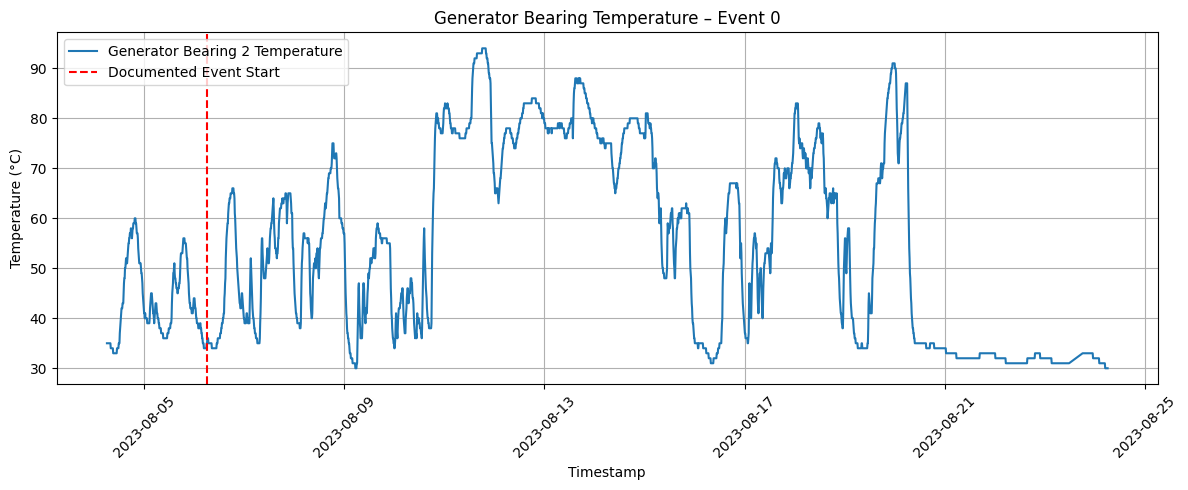

In [27]:
import matplotlib.pyplot as plt

# Load generator bearing temperature data
bearing_data = pd.read_csv(
    sample_file,
    sep=";",
    usecols=[
        "time_stamp",
        "train_test",
        "sensor_13_avg"
    ],
    parse_dates=["time_stamp"]
)

# Select prediction period
bearing_prediction = bearing_data[
    bearing_data["train_test"] == "prediction"
].sort_values("time_stamp")

# Get documented event start
event_start = pd.to_datetime(
    event_0.iloc[0]["event_start"]
)

# Plot generator bearing temperature
plt.figure(figsize=(12, 5))

plt.plot(
    bearing_prediction["time_stamp"],
    bearing_prediction["sensor_13_avg"],
    label="Generator Bearing 2 Temperature"
)

plt.axvline(
    event_start,
    color="red",
    linestyle="--",
    label="Documented Event Start"
)

plt.title("Generator Bearing Temperature – Event 0")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

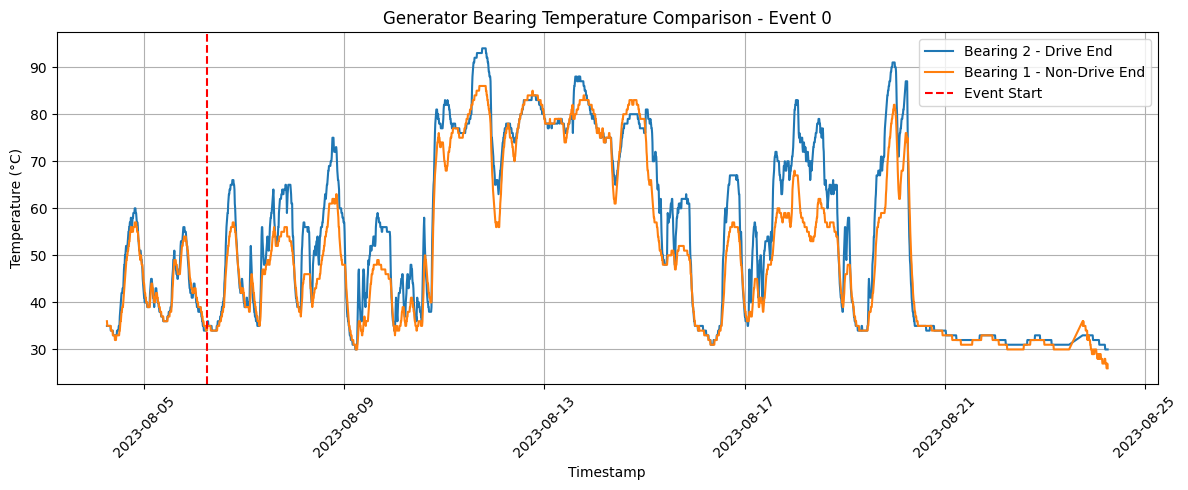

In [28]:
# Load generator bearing temperatures
bearing_comparison = pd.read_csv(
    sample_file,
    sep=";",
    usecols=[
        "time_stamp",
        "train_test",
        "sensor_13_avg",
        "sensor_14_avg"
    ],
    parse_dates=["time_stamp"]
)

# Select prediction period
bearing_comparison = bearing_comparison[
    bearing_comparison["train_test"] == "prediction"
].sort_values("time_stamp")

# Plot both generator bearing temperatures
plt.figure(figsize=(12, 5))

plt.plot(
    bearing_comparison["time_stamp"],
    bearing_comparison["sensor_13_avg"],
    label="Bearing 2 - Drive End"
)

plt.plot(
    bearing_comparison["time_stamp"],
    bearing_comparison["sensor_14_avg"],
    label="Bearing 1 - Non-Drive End"
)

# Mark documented event start
plt.axvline(
    event_start,
    color="red",
    linestyle="--",
    label="Event Start"
)

plt.title("Generator Bearing Temperature Comparison - Event 0")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
# Calculate the temperature difference between generator bearings
bearing_comparison["temperature_difference"] = (
    bearing_comparison["sensor_13_avg"]
    - bearing_comparison["sensor_14_avg"]
)

# Calculate descriptive statistics
difference_stats = (
    bearing_comparison["temperature_difference"]
    .describe()
)

print("Generator bearing temperature difference statistics:")
print(difference_stats.round(2))

Generator bearing temperature difference statistics:
count    2837.00
mean        3.64
std         4.99
min        -9.00
25%         0.00
50%         1.00
75%         8.00
max        20.00
Name: temperature_difference, dtype: float64


In [30]:
# Load bearing temperatures and operating status
bearing_status = pd.read_csv(
    sample_file,
    sep=";",
    usecols=[
        "train_test",
        "status_type_id",
        "sensor_13_avg",
        "sensor_14_avg"
    ]
)

# Select prediction data
bearing_status = bearing_status[
    bearing_status["train_test"] == "prediction"
].copy()

# Calculate bearing temperature difference
bearing_status["temperature_difference"] = (
    bearing_status["sensor_13_avg"]
    - bearing_status["sensor_14_avg"]
)

# Calculate statistics by operating status
status_difference_stats = (
    bearing_status.groupby("status_type_id")["temperature_difference"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print("Temperature difference by operating status:")
display(status_difference_stats)

Temperature difference by operating status:


,count,mean,median,std,min,max
status_type_id,,,,,,
0,288,0.56,0.0,1.69,-3.0,5.0
3,343,0.89,1.0,1.14,-3.0,4.0
4,2206,4.47,3.0,5.33,-9.0,20.0


In [31]:
# Load bearing temperatures and operating status
normal_bearing_data = pd.read_csv(
    sample_file,
    sep=";",
    usecols=[
        "train_test",
        "status_type_id",
        "sensor_13_avg",
        "sensor_14_avg"
    ]
)

# Select normal operation only
normal_bearing_data = normal_bearing_data[
    normal_bearing_data["status_type_id"] == 0
].copy()

# Calculate temperature difference
normal_bearing_data["temperature_difference"] = (
    normal_bearing_data["sensor_13_avg"]
    - normal_bearing_data["sensor_14_avg"]
)

# Compare training and prediction periods
normal_comparison = (
    normal_bearing_data
    .groupby("train_test")["temperature_difference"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print("Normal operation temperature difference comparison:")
display(normal_comparison)

Normal operation temperature difference comparison:


,count,mean,median,std,min,max
train_test,,,,,,
prediction,288,0.56,0.0,1.69,-3.0,5.0
train,47252,1.14,1.0,4.73,-15.0,22.0


In [32]:
# Calculate temperature difference quantiles
difference_quantiles = (
    normal_bearing_data
    .groupby("train_test")["temperature_difference"]
    .quantile([0.05, 0.25, 0.50, 0.75, 0.95])
    .unstack()
)

# Rename quantile columns
difference_quantiles.columns = [
    "P05", "P25", "P50", "P75", "P95"
]

print("Temperature difference quantiles by data split:")
display(difference_quantiles.round(2))

Temperature difference quantiles by data split:


,P05,P25,P50,P75,P95
train_test,,,,,
prediction,-2.0,-1.0,0.0,2.0,4.0
train,-7.0,-2.0,1.0,4.0,10.0


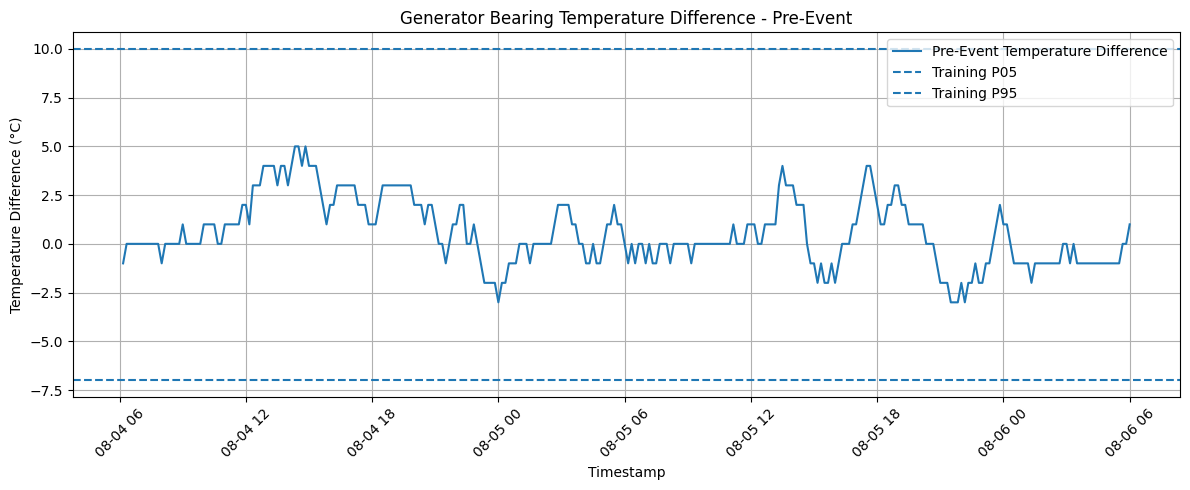

In [33]:
# Select observations before the documented event start
pre_event_data = bearing_comparison[
    bearing_comparison["time_stamp"] < event_start
].sort_values("time_stamp").copy()

# Get training quantile reference values
train_p05 = difference_quantiles.loc["train", "P05"]
train_p95 = difference_quantiles.loc["train", "P95"]

# Plot pre-event bearing temperature difference
plt.figure(figsize=(12, 5))

plt.plot(
    pre_event_data["time_stamp"],
    pre_event_data["temperature_difference"],
    label="Pre-Event Temperature Difference"
)

# Display training reference quantiles
plt.axhline(
    train_p05,
    linestyle="--",
    label="Training P05"
)

plt.axhline(
    train_p95,
    linestyle="--",
    label="Training P95"
)

plt.title("Generator Bearing Temperature Difference - Pre-Event")
plt.xlabel("Timestamp")
plt.ylabel("Temperature Difference (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

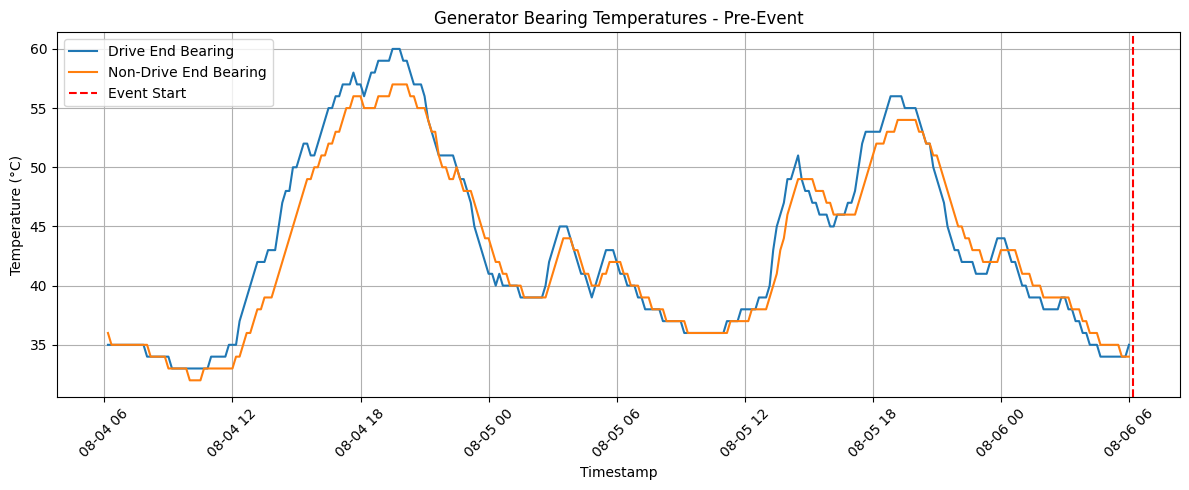

In [34]:
# Plot individual bearing temperatures before event start
plt.figure(figsize=(12, 5))

plt.plot(
    pre_event_data["time_stamp"],
    pre_event_data["sensor_13_avg"],
    label="Drive End Bearing"
)

plt.plot(
    pre_event_data["time_stamp"],
    pre_event_data["sensor_14_avg"],
    label="Non-Drive End Bearing"
)

# Mark documented event start
plt.axvline(
    event_start,
    color="red",
    linestyle="--",
    label="Event Start"
)

plt.title("Generator Bearing Temperatures - Pre-Event")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
# Calculate absolute bearing temperature quantiles
temperature_quantiles = (
    normal_bearing_data
    .groupby("train_test")[
        ["sensor_13_avg", "sensor_14_avg"]
    ]
    .quantile([0.05, 0.50, 0.95])
    .round(2)
)

print("Absolute bearing temperature quantiles:")
display(temperature_quantiles)

Absolute bearing temperature quantiles:


sensor_13_avg  sensor_14_avg
train_test                                   
prediction 0.05           34.0           33.0
           0.50           41.5           41.0
           0.95           57.0           55.0
train      0.05           26.0           25.0
           0.50           43.0           42.0
           0.95           73.0           71.0

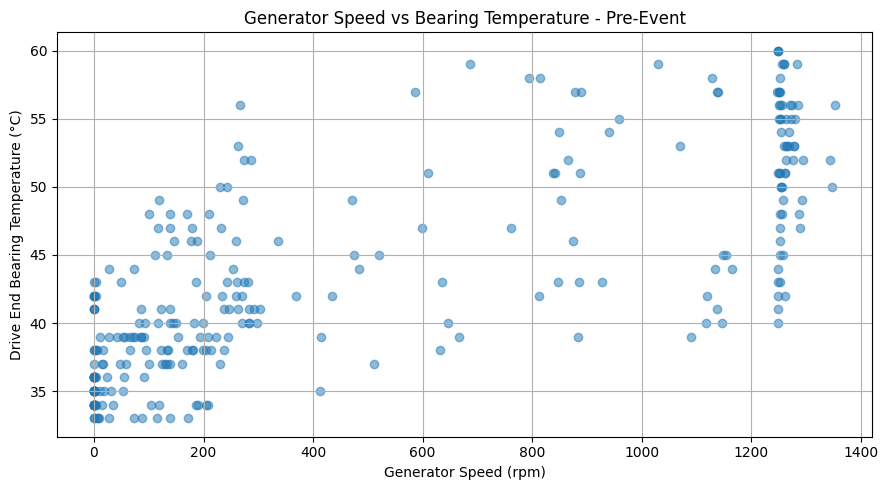

In [36]:
# Load generator speed and bearing temperature
speed_temperature_data = pd.read_csv(
    sample_file,
    sep=";",
    usecols=[
        "train_test",
        "status_type_id",
        "sensor_18_avg",
        "sensor_13_avg"
    ]
)

# Select normal operation during prediction
pre_event_speed = speed_temperature_data[
    (speed_temperature_data["train_test"] == "prediction")
    & (speed_temperature_data["status_type_id"] == 0)
].copy()

# Plot generator speed vs bearing temperature
plt.figure(figsize=(9, 5))

plt.scatter(
    pre_event_speed["sensor_18_avg"],
    pre_event_speed["sensor_13_avg"],
    alpha=0.5
)

plt.title("Generator Speed vs Bearing Temperature - Pre-Event")
plt.xlabel("Generator Speed (rpm)")
plt.ylabel("Drive End Bearing Temperature (°C)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [37]:
# Calculate Pearson correlation
correlation = pre_event_speed[
    ["sensor_18_avg", "sensor_13_avg"]
].corr(method="pearson")

print("Generator speed and bearing temperature correlation:")
display(correlation.round(3))

Generator speed and bearing temperature correlation:


,sensor_18_avg,sensor_13_avg
sensor_18_avg,1.000,0.761
sensor_13_avg,0.761,1.000


In [38]:
# Inspect Wind Farms B and C
for farm_name in ["Wind Farm B", "Wind Farm C"]:
    farm_path = data_path / farm_name
    datasets_path_farm = farm_path / "datasets"

    # Count SCADA datasets
    csv_files = list(datasets_path_farm.glob("*.csv"))

    print(f"\n{farm_name}")
    print("SCADA dataset count:", len(csv_files))

    # List metadata files
    print("Metadata files:")
    for file in sorted(farm_path.glob("*.csv")):
        print("-", file.name)


Wind Farm B
SCADA dataset count: 15
Metadata files:
- event_info.csv
- feature_description.csv

Wind Farm C
SCADA dataset count: 58
Metadata files:
- event_info.csv
- feature_description.csv


In [39]:
# Analyze event labels in Wind Farms B and C
for farm_name in ["Wind Farm B", "Wind Farm C"]:

    # Define event metadata path
    event_path = data_path / farm_name / "event_info.csv"

    # Load event metadata
    events = pd.read_csv(event_path, sep=";")

    print(f"\n{farm_name}")
    print("Number of events:", len(events))

    print("\nEvent label distribution:")
    print(events["event_label"].value_counts(dropna=False))


Wind Farm B
Number of events: 15

Event label distribution:
event_label
normal     9
anomaly    6
Name: count, dtype: int64

Wind Farm C
Number of events: 58

Event label distribution:
event_label
normal     31
anomaly    27
Name: count, dtype: int64


In [40]:
# Validate event labels across all wind farms
farm_names = ["Wind Farm A", "Wind Farm B", "Wind Farm C"]

for farm_name in farm_names:
    event_path = data_path / farm_name / "event_info.csv"
    events = pd.read_csv(event_path, sep=";")

    # Identify missing or unexpected labels
    invalid_labels = events[
        ~events["event_label"].isin(["normal", "anomaly"])
    ]

    print(f"{farm_name}:")
    print("Invalid or missing labels:", len(invalid_labels))
    print("Unique labels:", events["event_label"].unique())
    print()

Wind Farm A:
Invalid or missing labels: 0
Unique labels: ['anomaly' 'normal']

Wind Farm B:
Invalid or missing labels: 0
Unique labels: ['anomaly' 'normal']

Wind Farm C:
Invalid or missing labels: 0
Unique labels: ['anomaly' 'normal']



In [41]:
# Inspect event metadata columns for Wind Farms B and C
for farm_name in ["Wind Farm B", "Wind Farm C"]:

    event_path = data_path / farm_name / "event_info.csv"

    events = pd.read_csv(event_path, sep=";")

    print(f"\n{farm_name}")
    print("Columns:", events.columns.tolist())


Wind Farm B
Columns: ['asset_id', 'event_id', 'event_label', 'event_start', 'event_start_id', 'event_end', 'event_end_id', 'event_description']

Wind Farm C
Columns: ['asset_id', 'event_id', 'event_label', 'event_start', 'event_start_id', 'event_end', 'event_end_id', 'event_description']


In [42]:
# Count unique turbines in Wind Farms B and C
for farm_name in ["Wind Farm B", "Wind Farm C"]:

    event_path = data_path / farm_name / "event_info.csv"

    events = pd.read_csv(event_path, sep=";")

    # Count unique turbine IDs
    turbine_count = events["asset_id"].nunique()

    print(f"\n{farm_name}")
    print("Number of events:", len(events))
    print("Number of unique turbines:", turbine_count)

    print("\nEvents per turbine:")
    print(events["asset_id"].value_counts().sort_index())


Wind Farm B
Number of events: 15
Number of unique turbines: 9

Events per turbine:
asset_id
0     1
2     1
5     1
6     2
7     2
11    2
12    2
13    2
14    2
Name: count, dtype: int64

Wind Farm C
Number of events: 58
Number of unique turbines: 22

Events per turbine:
asset_id
2     2
5     1
12    3
13    1
14    1
15    2
16    4
21    2
23    3
32    2
33    2
34    4
35    4
38    2
42    2
43    4
44    2
50    2
52    4
53    6
55    3
56    2
Name: count, dtype: int64


In [43]:
# Inspect SCADA column counts in Wind Farms B and C
for farm_name in ["Wind Farm B", "Wind Farm C"]:

    # Select the first SCADA dataset
    farm_path = data_path / farm_name / "datasets"
    sample_csv = sorted(farm_path.glob("*.csv"))[0]

    # Read only the CSV header
    columns = pd.read_csv(
        sample_csv,
        sep=";",
        nrows=0
    ).columns

    print(f"\n{farm_name}")
    print("Sample file:", sample_csv.name)
    print("Number of columns:", len(columns))
    print("First 5 columns:", columns[:5].tolist())


Wind Farm B
Sample file: 19.csv
Number of columns: 257
First 5 columns: ['time_stamp', 'asset_id', 'id', 'train_test', 'status_type_id']

Wind Farm C
Sample file: 1.csv
Number of columns: 957
First 5 columns: ['time_stamp', 'asset_id', 'id', 'train_test', 'status_type_id']


## 10. Cross-Farm Dataset Comparison

### 10.1 Dataset Overview and Key Findings

The CARE-to-Compare v6 dataset contains 95 event
datasets from 36 wind turbines across three wind farms.

| Metric | Farm A | Farm B | Farm C |
|---|---:|---:|---:|
| Datasets | 22 | 15 | 58 |
| Turbines | 5 | 9 | 22 |
| Anomaly events | 12 | 6 | 27 |
| Normal events | 10 | 9 | 31 |
| CSV columns (sample) | 86 | 257 | 957 |

### Key Findings

- All 95 expected event datasets are present.
- The number of turbines matches the documentation.
- The wind farms have different feature dimensions.
- Wind Farm A uses `asset` in event metadata,
  while Wind Farms B and C use `asset_id`.
- All event labels are valid.
- Event metadata contains 45 anomaly events and
  50 normal events, whereas the README reports
  44 anomaly events and 51 normal events.
- The label count discrepancy requires further
  investigation.
- Column counts for Wind Farms B and C were
  verified using one sample CSV per wind farm.

## 11. Key Findings and Conclusions

### 11.1 Dataset Understanding

The CARE-to-Compare v6 dataset was explored to understand its structure, event metadata, SCADA measurements, and data quality.

**Key findings:**

- The dataset contains 95 event datasets from 36 wind turbines across three wind farms.
- Wind Farm A contains 22 datasets, Wind Farm B contains 15, and Wind Farm C contains 58.
- Sample SCADA files contain 86, 257, and 957 columns for Wind Farms A, B, and C, respectively.
- Event metadata contains 45 anomaly events and 50 normal events, while the README reports 44 anomalies and 51 normal events.
- The turbine identifier column differs between wind farms (`asset` versus `asset_id`).

### 11.2 Data Quality Findings

A detailed data quality analysis was performed on Wind Farm A, Event 0 (`0.csv`).

**Results:**

- 54,986 SCADA observations and 81 sensor features.
- 52,148 training observations and 2,838 prediction observations.
- No duplicate timestamps.
- 18 irregular time intervals.
- 455 potentially missing timestamps, assuming a continuous 10-minute sampling grid.
- Two missing sensor values affecting one observation during the prediction period.
- Missing sensor values occurred during the Downtime operating state.

The original SCADA files were not modified.

### 11.3 Operating Status and Event Analysis

Event 0 is labeled as a generator bearing failure.

The documented event start coincides with the first observed transition from Normal Operation to Downtime.

However, the turbine remained in Downtime after the documented event end.

**Conclusion:** Event labels and operating status information must be interpreted separately.

### 11.4 Sensor Exploration

Generator bearing temperatures and generator speed were examined.

**Key findings:**

- Both generator bearing temperatures often followed similar patterns.
- Temperature differences were generally larger during Downtime than during Normal Operation.
- No clear pre-event warning pattern was identified from the examined temperature statistics and plots.
- Generator speed and Drive-End bearing temperature showed a positive Pearson correlation of 0.761 during the pre-event prediction period.

The observed correlation does not establish causality or prove predictive capability.

### 11.5 Limitations

- Detailed sensor and temporal analyses focused on a single event dataset.
- Operating status 0 does not guarantee healthy operation.
- The cause of missing measurements remains unknown.
- Possible timestamp anonymization and daylight-saving effects require consideration.
- The discrepancy between README label counts and event metadata remains unresolved.
- The column counts for Wind Farms B and C were checked using sample files rather than every SCADA file.

### 11.6 Next Steps

The next project phase should focus on selecting a suitable subset for machine learning and developing an initial, leakage-aware Normal Behavior Modeling approach.

Before model development, training data selection, temporal validation, and operating-condition dependencies must be carefully considered.